# **1. Introduction**

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification and regression.

In this project, we use KNN to predict whether a patient has diabetes based on medical measurements.

The model identifies the K nearest data points and predicts the class based on the majority class among those neighbors.

# **2. Import Libraries**

Import the required libraries for data manipulation, visualization, preprocessing, model training, cross-validation, and evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# **3. Load Dataset**

Load the Pima Indians Diabetes dataset downloaded from Kaggle.

The CSV file has no column headers, so we provide the standard column names manually.

In [ ]:
file_path = "/content/drive/MyDrive/Data Science Projeccts/Algorithm/pima-indians-diabetes/pima-indians-diabetes.csv"

# Define the column names
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Load the dataset without treating the first row as a header
df = pd.read_csv(
    file_path,
    header=None,
    names=columns
)

print("Dataset uploaded successfully")

Dataset uploaded successfully


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# **4. Understand the Dataset**

Display the number of rows and columns, inspect the data types, and check whether the dataset contains missing values.

In [ ]:

print("Dataset Shape:", df.shape)

Dataset Shape: (768, 9)


In [ ]:
# Display column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
# Check missing values in each column
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# **5. Statistical Summary**

Use describe() to calculate statistical measures such as mean, standard deviation, minimum, maximum, and quartiles for each numerical column.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


# **6. Target Distribution**

The Outcome column is the target variable.

- 0 represents a patient without diabetes.
- 1 represents a patient with diabetes.

Check the number of observations in each class to understand the class distribution.

In [ ]:

print(df["Outcome"].value_counts())

# Calculate the percentage of each class
print(df["Outcome"].value_counts(normalize=True) * 100)


Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


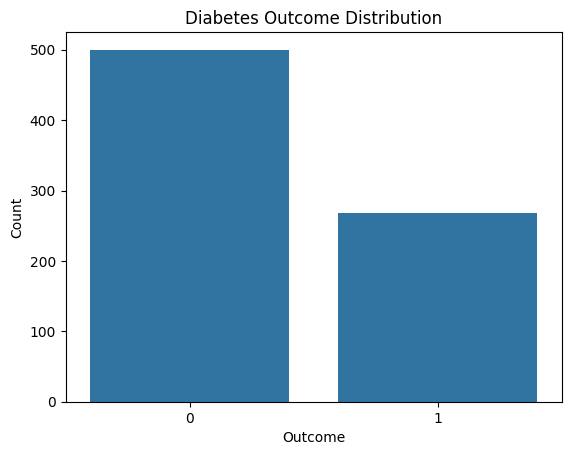

In [ ]:
# Visualize the target distribution
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

# **7. Check Invalid Zero Values**

In this dataset, zero is a valid value for Pregnancies but is generally not a meaningful measurement for Glucose, BloodPressure, SkinThickness, Insulin, and BMI.

I will treat zeros in these five medical measurement columns as missing values and impute them later using the median.

I will not replace zeros in Pregnancies, DiabetesPedigreeFunction, or Age.

In [ ]:
# Columns where zero represents a missing or invalid measurement
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Count zeros in each selected column
(df[zero_columns] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


# **8. Separate Features and Target**

The input features (X) contain the medical measurements used for prediction.

The target (y) is the Outcome column, which indicates whether a patient has diabetes.

In [ ]:
# Separate input features and target variable
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Replace invalid zeros with NaN in the selected columns
X[zero_columns] = X[zero_columns].replace(0, np.nan)


X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


# **9. Train-Test Split**

Split the dataset into training and testing sets.

- Training set: Used to train the model.
- Testing set: Used to evaluate the model on unseen data.

I will use stratify=y to maintain approximately the same proportion of both classes in the training and testing sets.

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


# **10. Build the KNN Pipeline**

KNN calculates distances between data points, so feature scaling is important.

I will create a Pipeline containing three steps:

1. SimpleImputer: Replaces missing values with the median of each feature.
2. StandardScaler: Standardizes features so they have comparable scales.
3. KNeighborsClassifier: Predicts the class using the nearest neighbors.

Using a Pipeline ensures that preprocessing is fitted separately within each cross-validation training fold, helping prevent data leakage.

In [ ]:
# Create a pipeline for preprocessing and KNN classification
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

knn_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

# **11. Hyperparameter Tuning Using Cross-Validation**

The value of K represents the number of nearest neighbors considered when making a prediction.

A very small K may be sensitive to noise, while a very large K may overlook local patterns.

I will use GridSearchCV with 5-fold Stratified Cross-Validation to compare different odd values of K.

The model is selected using the F1-score because it balances precision and recall, which are useful when evaluating diabetes classification.

In [ ]:
# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Test different values of K
param_grid = {
    "knn__n_neighbors": list(range(3, 26, 2))
}

# Evaluate using F1-score
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring={
        "F1": "f1"
    },
    refit="F1",
    cv=cv,
    n_jobs=-1
)

# Train and compare the models
grid_search.fit(X_train, y_train)

# Display the best K and evaluation metrics
best_index = grid_search.best_index_

print("Best K:", grid_search.best_params_["knn__n_neighbors"])
print("Best Cross-Validation F1-Score:", grid_search.cv_results_["mean_test_F1"][best_index])


Best K: 13
Best Cross-Validation F1-Score: 0.6531977789657385


# **12. Compare Cross-Validation Results**

Display the cross-validation results for the different values of K.

This helps us understand how changing the number of neighbors affects the model's F1-score.

In [ ]:

# Convert cross-validation results into a DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

# Select the relevant columns
cv_results = cv_results[
    [
        "param_knn__n_neighbors",
        "mean_test_F1",
        "std_test_F1"
    ]
]

# Rename the columns for clarity
cv_results.columns = [
    "K",
    "F1-Score",
    "Standard Deviation"
]

# Display the results
cv_results


,K,F1-Score,Standard Deviation
0,3,0.580860,0.073924
1,5,0.593861,0.046870
2,7,0.600505,0.030699
3,9,0.624809,0.037895
4,11,0.610911,0.047728
5,13,0.653198,0.051468
6,15,0.631865,0.048030
7,17,0.625491,0.035395
8,19,0.604645,0.033900
9,21,0.600174,0.028045


# **13. Visualize K Selection**

Plot the mean cross-validation F1-score for each value of K.

The highest point indicates the K value with the best mean cross-validation F1-score among the tested values.

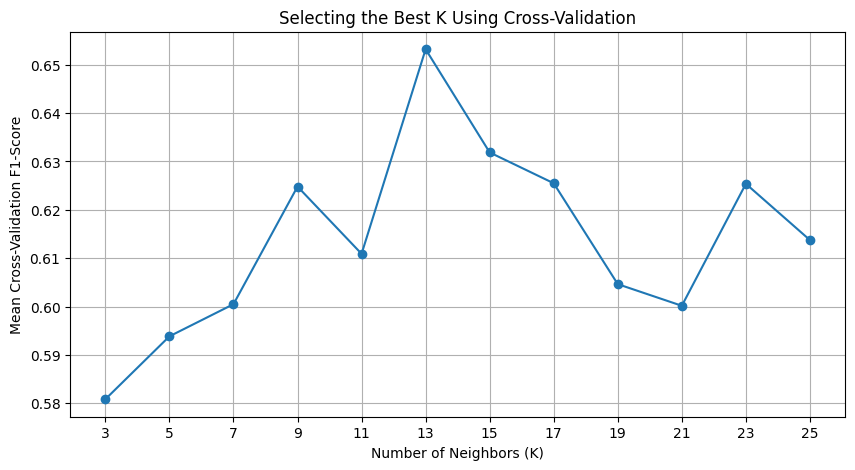

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    cv_results["K"],
    cv_results["F1-Score"],
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation F1-Score")
plt.title("Selecting the Best K Using Cross-Validation")
plt.xticks(cv_results["K"])
plt.grid(True)
plt.show()

# **14. Select the Best KNN Model**

GridSearchCV has identified the best K based on the mean cross-validation F1-score.

The best estimator includes the complete preprocessing pipeline and the selected KNN model.

In [ ]:
# Retrieve the best pipeline found during cross-validation
best_knn = grid_search.best_estimator_

print("Best Model:")
print(best_knn)

Best Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=13))])


# **15. Make Predictions**

Use the selected model to predict the diabetes outcome for the unseen testing data.

The fitted pipeline automatically handles missing-value imputation and feature standardization before making predictions.

In [ ]:
# Predict the outcomes for the testing data
y_pred = best_knn.predict(X_test)

# Display the first ten actual and predicted values
results = pd.DataFrame({
    "Actual Outcome": y_test.to_numpy()[:10],
    "Predicted Outcome": y_pred[:10]
})

results

,Actual Outcome,Predicted Outcome
0,0,1
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,1,0
7,1,1
8,0,0
9,0,1


# **16. Model Evaluation**

Evaluate the model using the following metrics:

- Accuracy: Proportion of all predictions that are correct.
- Precision: Proportion of predicted positive cases that are actually positive.
- Recall: Proportion of actual positive cases correctly identified.
- F1-Score: Harmonic mean of precision and recall.

These metrics provide a broader view of model performance than accuracy alone.

In [ ]:
# Calculate classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Store the results in a DataFrame
evaluation = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

evaluation

,Metric,Score
0,Accuracy,0.714286
1,Precision,0.608696
2,Recall,0.518519
3,F1-Score,0.560000


# **17. Classification Report**

Display precision, recall, F1-score, and the number of observations for each class.

This report helps us understand how well the model identifies patients with and without diabetes.

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

              precision    recall  f1-score   support

 No Diabetes       0.76      0.82      0.79       100
    Diabetes       0.61      0.52      0.56        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



# **18. Confusion Matrix**

A confusion matrix compares actual classes with predicted classes.

- True Negative (TN): Correctly predicted no diabetes.
- False Positive (FP): Predicted diabetes when the patient does not have diabetes.
- False Negative (FN): Failed to identify a patient who has diabetes.
- True Positive (TP): Correctly predicted diabetes.

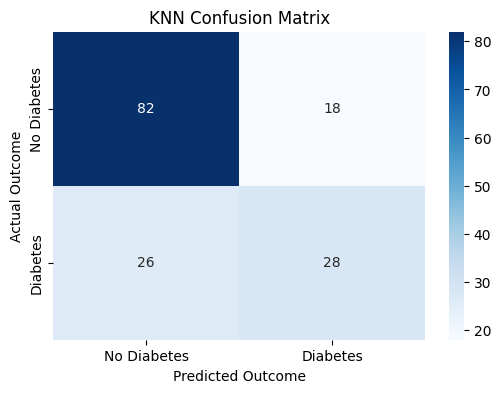

In [ ]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("KNN Confusion Matrix")
plt.show()

# **19. ROC Curve and AUC**

The ROC curve illustrates how the true positive rate changes against the false positive rate at different classification thresholds.

The AUC (Area Under the Curve) summarizes the model's ability to distinguish between the two classes. A higher AUC generally indicates better class discrimination.

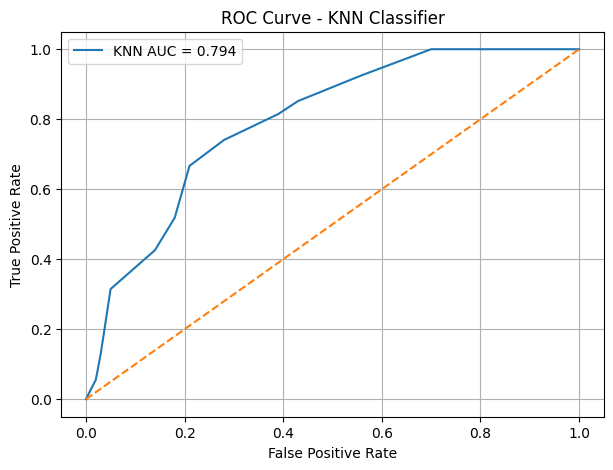

ROC-AUC Score: 0.7944444444444444


In [ ]:
# Obtain predicted probabilities for the positive class
y_probability = best_knn.predict_proba(X_test)[:, 1]

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_probability)

# Plot the ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"KNN AUC = {auc_score:.3f}"
)

# Plot the reference line
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN Classifier")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", auc_score)

# **20. Why Feature Scaling Matters in KNN**

KNN uses distances to determine which observations are nearest to each other.

Features with larger numerical ranges can dominate distance calculations if scaling is not applied.

StandardScaler transforms features using their training-set mean and standard deviation. In our Pipeline, the scaler is fitted on the training data and then applied to the testing data.

# **21. Conclusion**

In this project, I implemented a K-Nearest Neighbors classifier using the Pima Indians Diabetes dataset from Kaggle.

I performed exploratory data analysis, handled invalid zero measurements, and used a Pipeline for median imputation and feature standardization.

I applied 5-fold Stratified Cross-Validation with GridSearchCV to select the best value of K based on the F1-score.

Finally, I evaluated the selected model using accuracy, precision, recall, F1-score, a confusion matrix, and the ROC-AUC score.

This project helped me understand how KNN works, why feature scaling is important, and how cross-validation can be used to select model hyperparameters.